<a href="https://colab.research.google.com/github/05haileywang/Econ_3916_PS4/blob/main/ps4_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [22]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [23]:
import numpy as np
import pandas as pd

# Set up
rng = np.random.default_rng(42)

# Store characteristics
floor_area = rng.uniform(1000, 10000, N_STORES)
foot_traffic = 500 + 0.8 * floor_area + rng.normal(0, 500, N_STORES)
median_income = rng.normal(70000, 15000, N_STORES)
years_open = rng.integers(1, 31, N_STORES)

# Three irrelevant predictors
noise1 = rng.normal(0, 1, N_STORES)
noise2 = rng.normal(0, 1, N_STORES)
noise3 = rng.normal(0, 1, N_STORES)

# Nearly collinear predictor
collinear = floor_area + 0.5 * foot_traffic + rng.normal(0, 50, N_STORES)

# Revenue with diminishing returns and increasing variance
revenue = (
    20000
    + 120 * floor_area
    - 0.006 * floor_area**2
    + 25 * foot_traffic
    + 1.5 * median_income
    + 1500 * years_open
    + rng.normal(0, 15000 + 4 * floor_area, N_STORES)
)

# Create DataFrame
df = pd.DataFrame({
    "floor_area": floor_area,
    "foot_traffic": foot_traffic,
    "median_income": median_income,
    "years_open": years_open,
    "noise1": noise1,
    "noise2": noise2,
    "noise3": noise3,
    "collinear": collinear,
    "revenue": revenue
})

# Separate predictors and outcome
X = df.drop(columns="revenue")
y = df["revenue"]

# Preview data
print("Number of stores:", len(df))
print("Number of predictors:", X.shape[1])
display(df.head())

Number of stores: 400
Number of predictors: 8


,floor_area,foot_traffic,median_income,years_open,noise1,noise2,noise3,collinear,revenue
0,7965.604,7092.302,70663.186,18,-0.317,-2.436,-1.862,11507.407,896302.398
1,4949.906,4722.019,66956.290,27,-0.165,-0.983,-1.002,7327.906,734987.316
2,8727.381,7620.042,53763.592,24,-1.752,0.688,-1.741,12560.413,851480.437
3,7276.312,5614.667,67734.222,20,0.094,1.213,0.017,10133.363,827738.907
4,1847.596,823.025,58808.526,24,1.249,1.109,-0.122,2263.245,370732.238


*The data-generating process, recorded: every predictor and the true revenue equation.*


I simulated data for 400 stores using floor area, foot traffic, local median income, and years open as predictors of average expected revenue. I included 3 irrelevant variables to see if they would affect model fit. I also created a collinear variable using floor area and foot traffic to introduce multicollinearity. Revenue increases with floor area, but the negative squared term means that revenue increases at a slower rate as stores become larger. The variance of the error term increases with floor area, which can be interpreted as larger stores having less consistent revenue. This will allow me to test whether the regression model can identify nonlinearity and heteroskedasticity.

Revenue = 20,000 + 120(Area) - 0.006(Area^2) + 25(Traffic) + 1.5(Income) + 1500(Years) + Error

### Step 1.2: Fit it the way they did (12 pts)

In [24]:
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# OLS on all 400 stores
ols = sm.OLS(y, sm.add_constant(X)).fit()

print("Full sample R-squared:", round(ols.rsquared, 4))

# 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# OLS using only the training data
ols_train = sm.OLS(y_train, sm.add_constant(X_train)).fit()

# Predict revenue for the test stores
y_pred = ols_train.predict(sm.add_constant(X_test))

# R-squared
train_r2 = ols_train.rsquared
test_r2 = r2_score(y_test, y_pred)

print("Training R-squared:", round(train_r2, 4))
print("Test R-squared:", round(test_r2, 4))
print("Train-test gap:", round(train_r2 - test_r2, 4))
print("Full sample vs test gap:", round(ols.rsquared - test_r2, 4))

Full sample R-squared: 0.9374
Training R-squared: 0.9362
Test R-squared: 0.9379
Train-test gap: -0.0016
Full sample vs test gap: -0.0005


*Your answer here.*

The full OLS model has an R-squared of 0.9374, which means that the model is able to explain 93.74% of the variation in store revenue. This R-squared is similar to the 0.94 that was reported by the previous analysis. A high R-squared means the model fits the existing data well, but it does not necessarily mean that it will make accurate predictions for new stores.

To test the fit, I split the data into 70% training and 30% testing. The training R-squared was 0.9362 and the testing R-squared was 0.9379.The train-test gap is -0.0016, which means that the model performed a little better on the testing data. However, the gap is small, which suggests that the model performs similarly on both datasets.

Even with a high R-squared value, there could be patterns in the errors, especially when looking at larger stores. Analyzing the residuals can help us to understand if the model is under or overestimating the revenue.

### Step 1.3: Say what R-squared is (8 pts)

In [25]:
import numpy as np
import statsmodels.api as sm

# Original model
original = sm.OLS(y, sm.add_constant(X)).fit()

# Add three random noise variables
X_noise = X.copy()
rng_noise = np.random.default_rng(123)

X_noise["random1"] = rng_noise.normal(0, 1, len(X))
X_noise["random2"] = rng_noise.normal(0, 1, len(X))
X_noise["random3"] = rng_noise.normal(0, 1, len(X))

# OLS with the extra noise variables
new_model = sm.OLS(y, sm.add_constant(X_noise)).fit()

# Compare results
print("Original R-squared:", round(original.rsquared, 4))
print("New R-squared:", round(new_model.rsquared, 4))

print("\nOriginal adjusted R-squared:", round(original.rsquared_adj, 4))
print("New adjusted R-squared:", round(new_model.rsquared_adj, 4))

print("\nChange in R-squared:",
      round(new_model.rsquared - original.rsquared, 6))

print("Change in adjusted R-squared:",
      round(new_model.rsquared_adj - original.rsquared_adj, 6))

Original R-squared: 0.9374
New R-squared: 0.9376

Original adjusted R-squared: 0.9361
New adjusted R-squared: 0.9358

Change in R-squared: 0.000187
Change in adjusted R-squared: -0.000301


*Your answer here.*

The R-squared values for the training data cannot decrease when we add more predictors because the model could output a coefficient of 0 for those predictors. Adding more variables will keep the R-squared the same or increase.

After adding 3 random noise variables, the R-squared increased from 0.9374 to 0.9376, an increase of 0.000187. However, the adjusted R-squared decreased from 0.9361 to 0.9358, a decrease of 0.000301. Even though adding more variables increased the R-squared, it did not necessarily make the model better at predicting revenue.

The adjusted R-squared accounts for the number of predictors, so it can decrease when adding random noise variables that do not help explain revenue.

We cannot rely on just R-squared. We also need to consider the adjusted R-squared when determining the fit of the model.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

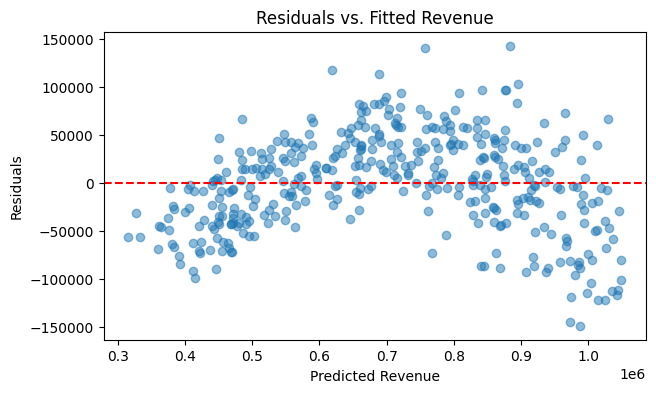

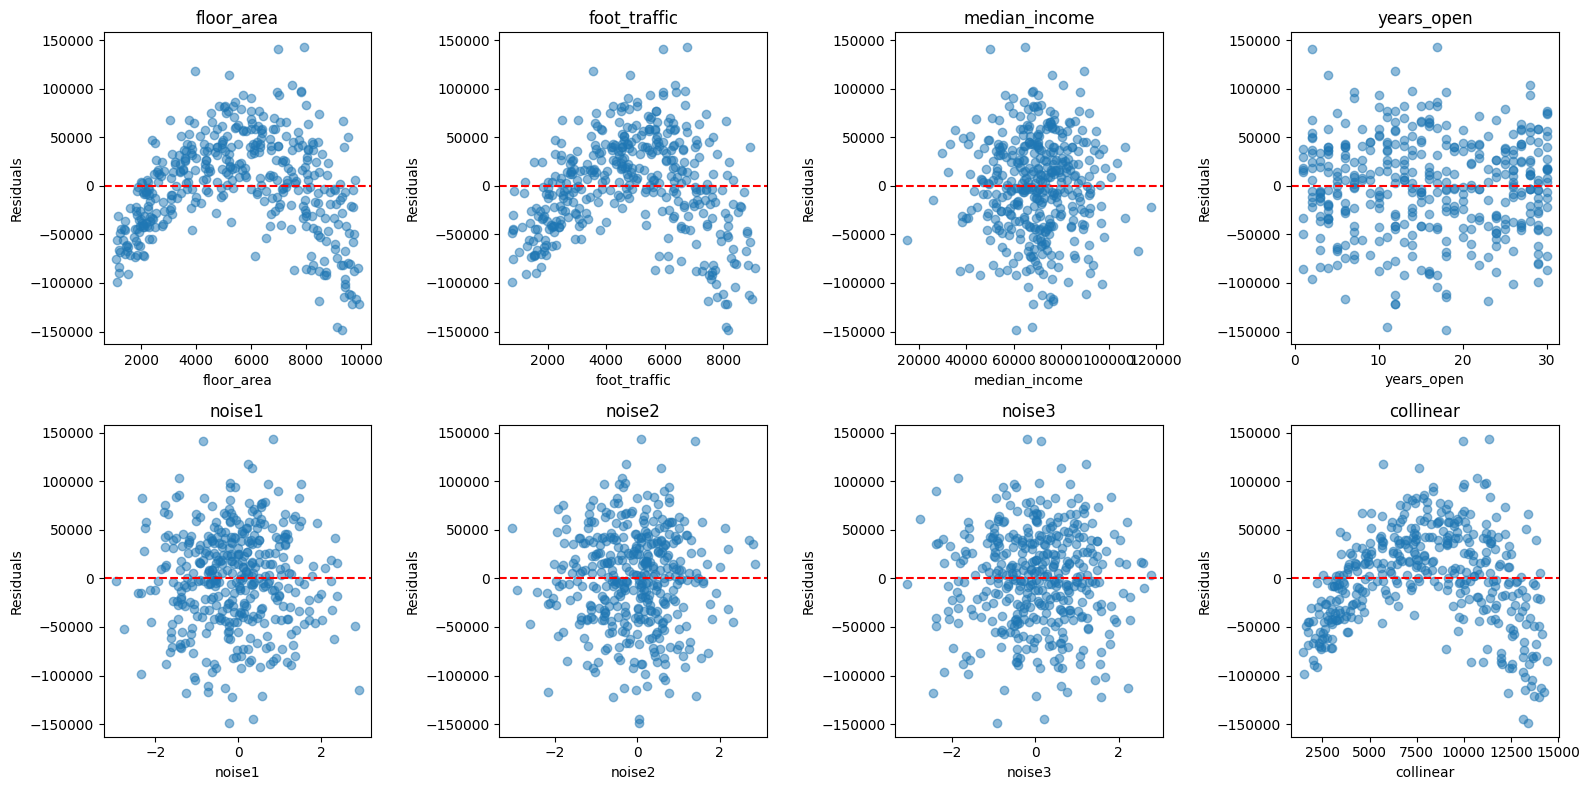

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# OLS using the original predictors
model = sm.OLS(y, sm.add_constant(X)).fit()

# Fitted revenue and residuals
fitted = model.fittedvalues
residuals = model.resid

# Plot residuals against fitted values
plt.figure(figsize=(7, 4))
plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Revenue")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Revenue")
plt.show()

# Plot residuals against each predictor
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, column in enumerate(X.columns):
    ax = axes.flat[i]
    ax.scatter(X[column], residuals, alpha=0.5)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel(column)
    ax.set_ylabel("Residuals")
    ax.set_title(column)

plt.tight_layout()
plt.show()

*Your answer here.*

After plotting the residuals, there is evidence of heteroskedasticity and nonlinearity.

Heteroskedasticity is when the variance of the errors is not constant. Larger stores tend to have a wider range of residuals, and the model has a harder time predicting the values for larger stores. This violates the constant variance assumption. Heteroskedasticity does not necessarily make the coefficients biased, but it can make the standard errors inaccurate, which can affect the reliability of our confidence intervals and hypothesis tests.

Nonlinearity is present because the model assumes that floor area has a linear relationship with revenue, but the actual relationship shows diminishing returns. This violates the assumption that the model correctly represents the relationship between the predictors and revenue. This can lead to biased coefficients because the model is missing an important relationship. The standard errors can also be inaccurate as a result.

Although the model has a high R-squared, it does not necessarily mean that it can make accurate predictions for each store.

### Step 2.2: The over-forecast on big stores (15 pts)

Average over-forecast by store size:
size_group
Small         29085.21
Medium       -28775.34
Large        -28854.53
Very Large    28544.67
Name: error, dtype: float64


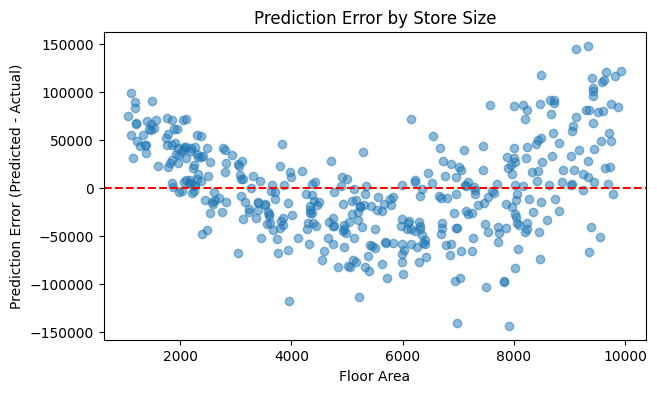


Variance Inflation Factors:
        Variable      VIF
0          const     1.00
1     floor_area  2694.01
2   foot_traffic   492.58
3  median_income     1.01
4     years_open     1.01
5         noise1     1.02
6         noise2     1.04
7         noise3     1.01
8      collinear  5340.70


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Fit the original OLS model
model = sm.OLS(y, sm.add_constant(X)).fit()

# Calculate prediction errors
results = pd.DataFrame({
    "floor_area": X["floor_area"],
    "actual": y,
    "predicted": model.predict(sm.add_constant(X))
})

results["error"] = results["predicted"] - results["actual"]

# Divide stores into four size groups
results["size_group"] = pd.qcut(
    results["floor_area"], 4,
    labels=["Small", "Medium", "Large", "Very Large"]
)

# Average error for each group
print("Average over-forecast by store size:")
print(results.groupby("size_group", observed=True)["error"].mean().round(2))

# Plot errors against store size
plt.figure(figsize=(7, 4))
plt.scatter(results["floor_area"], results["error"], alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Floor Area")
plt.ylabel("Prediction Error (Predicted - Actual)")
plt.title("Prediction Error by Store Size")
plt.show()

# Calculate VIF
X_vif = sm.add_constant(X)

vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print("\nVariance Inflation Factors:")
print(vif.round(2))

*Your answer here.*

After looking at the prediction errors for different store sizes, the model tends to overestimate the revenue for small and very large stores. For small stores, the model overestimated revenue by an average of 29,085.21. For very large stores, it overestimated revenue by 28,544.67. The model underestimated revenue for medium and large stores by 28,775.34 and 28,854.53. The average errors show a pattern across store sizes, suggesting that the model has trouble accounting for the nonlinear relationship between floor area and revenue.

The VIF for floor area was 2694.01, foot traffic was 492.58, and the collinear variable was 5340.70. These values are all very high, meaning that they are highly correlated with each other.

The high VIF means that the coefficients are less precise and their standard errors increase. Multicollinearity does not automatically make the coefficients biased or mean that the model makes inaccurate predictions. We should not just remove a variable, especially when it is an important predictor of revenue.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

Simple model training RMSE: 59170.28
Simple model testing RMSE: 54278.48

Polynomial model results:
 Degree  Training RMSE  Test RMSE
      1       50956.98   48191.91
      2       37614.76   35757.03
      3       37614.61   35751.69
      4       37597.30   35831.36
      5       37595.66   35873.49
      6       37557.32   35915.25
      7       37555.56   35930.13
      8       37468.54   36456.05
      9       37119.08   37204.34
     10       37004.69   37030.16


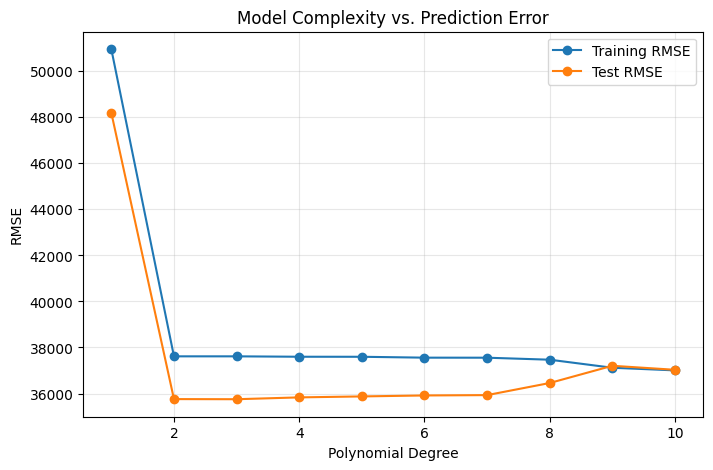


Lowest test RMSE: 35751.69
Degree with lowest test RMSE: 3


In [28]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Simple model using two predictors
simple_features = ["floor_area", "foot_traffic"]

simple_model = make_pipeline(StandardScaler(), LinearRegression())
simple_model.fit(X_train[simple_features], y_train)

simple_train_pred = simple_model.predict(X_train[simple_features])
simple_test_pred = simple_model.predict(X_test[simple_features])

simple_train_rmse = np.sqrt(mean_squared_error(y_train, simple_train_pred))
simple_test_rmse = np.sqrt(mean_squared_error(y_test, simple_test_pred))

print("Simple model training RMSE:", round(simple_train_rmse, 2))
print("Simple model testing RMSE:", round(simple_test_rmse, 2))

# Different polynomial degrees for floor area
degrees = range(1, 11)

train_errors = []
test_errors = []

for degree in degrees:

    # Polynomial terms for floor area
    poly = PolynomialFeatures(degree=degree, include_bias=False)

    train_area = poly.fit_transform(X_train[["floor_area"]])
    test_area = poly.transform(X_test[["floor_area"]])

    # Keep the other original predictors
    train_other = X_train.drop(columns="floor_area").values
    test_other = X_test.drop(columns="floor_area").values

    # Combine predictors
    X_train_poly = np.column_stack([train_area, train_other])
    X_test_poly = np.column_stack([test_area, test_other])

    # Fit the model
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(X_train_poly, y_train)

    # Predict revenue
    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    # Calculate RMSE
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    train_errors.append(train_rmse)
    test_errors.append(test_rmse)

# Show results
results = pd.DataFrame({
    "Degree": list(degrees),
    "Training RMSE": train_errors,
    "Test RMSE": test_errors
})

print("\nPolynomial model results:")
print(results.round(2).to_string(index=False))

# Plot training and test errors
plt.figure(figsize=(8, 5))

plt.plot(degrees, train_errors, marker="o", label="Training RMSE")
plt.plot(degrees, test_errors, marker="o", label="Test RMSE")

plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE")
plt.title("Model Complexity vs. Prediction Error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Find the degree with the lowest test error
lowest_test_degree = list(degrees)[np.argmin(test_errors)]

print("\nLowest test RMSE:", round(min(test_errors), 2))
print("Degree with lowest test RMSE:", lowest_test_degree)

*Your answer here.*

I compared models with different polynomial degrees from 1 to 10 to examine how increasing model complexity affects prediction accuracy. I also started with a simpler model using only floor area and foot traffic to compare it with the more complex models. The simpler model had a training RMSE of 59,170.28 and a testing RMSE of 54,278.48.

The testing RMSE decreased from 48,191.91 for degree 1 to 35,751.69 for degree 3, which had the lowest testing RMSE. Adding polynomial terms helped the model account for the nonlinear relationship between floor area and revenue. However, after degree 3, the testing RMSE generally increased while the training RMSE continued to decrease. This suggests that adding more complexity was starting to cause overfitting.

This shows the relationship between bias and variance. Simpler models tend to have higher bias because they cannot capture all the relationships in the data, which can lead to underfitting. As we add more polynomial terms, the model becomes more flexible and can better fit the training data. However, more complex models can also have higher variance because they start fitting random patterns in the training data, which can lead to overfitting and worse predictions on new data.

Overall, the results show that adding more complexity does not always improve the model. Even though degree 3 had the lowest testing RMSE, degree 2 had a testing RMSE of 35,757.03, which is only 5.34 higher. This suggests that degree 2 may be a better choice because it captures the nonlinear relationship without adding too many unnecessary terms.

### Step 3.2: Choose, and be honest about the estimate (11 pts)



In [29]:

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

# Polynomial degrees 1 through 10
for degree in range(1, 11):

    # Create polynomial terms for floor area
    poly = PolynomialFeatures(degree=degree, include_bias=False)

    train_area = poly.fit_transform(X_train[["floor_area"]])

    # Keep the other predictors
    train_other = X_train.drop(columns="floor_area").values

    # Combine predictors
    X_train_poly = np.column_stack([train_area, train_other])

    # Create regression model
    model = make_pipeline(StandardScaler(), LinearRegression())

    # Cross-validation RMSE
    scores = -cross_val_score(
        model,
        X_train_poly,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    cv_results.append({
        "Degree": degree,
        "Mean CV RMSE": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

# Compare cross-validation results
cv_table = pd.DataFrame(cv_results)
print(cv_table.round(2).to_string(index=False))

# Select degree with lowest mean CV error
best_degree = int(
    cv_table.loc[cv_table["Mean CV RMSE"].idxmin(), "Degree"]
)

print("\nSelected polynomial degree:", best_degree)

# Rebuild training and test data using selected degree
poly = PolynomialFeatures(degree=best_degree, include_bias=False)

train_area = poly.fit_transform(X_train[["floor_area"]])
test_area = poly.transform(X_test[["floor_area"]])

train_other = X_train.drop(columns="floor_area").values
test_other = X_test.drop(columns="floor_area").values

X_train_best = np.column_stack([train_area, train_other])
X_test_best = np.column_stack([test_area, test_other])

# Fit selected model on training data
best_model = make_pipeline(StandardScaler(), LinearRegression())
best_model.fit(X_train_best, y_train)

# Evaluate on held-out test data
test_predictions = best_model.predict(X_test_best)

test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

# Get the mean and standard deviation of the selected model's CV RMSE
best_row = cv_table.loc[cv_table["Mean CV RMSE"].idxmin()]
cv_mean = best_row["Mean CV RMSE"]
cv_sd = best_row["CV Standard Deviation"]

print("Selected model CV RMSE:", round(cv_mean, 2))
print("Held-out test RMSE:", round(test_rmse, 2))
print("CV RMSE standard deviation:", round(cv_sd, 2))

 Degree  Mean CV RMSE  CV Standard Deviation
      1      52851.41                2467.02
      2      39702.78                2058.84
      3      39938.10                2030.90
      4      40096.48                2028.94
      5      40237.48                1993.25
      6      40792.50                2222.62
      7      41297.34                2687.37
      8      41215.62                2567.52
      9      40356.45                1763.19
     10      40130.60                1617.37

Selected polynomial degree: 2
Selected model CV RMSE: 39702.78
Held-out test RMSE: 35757.03
CV RMSE standard deviation: 2058.84


In [30]:
from scipy import stats

# Squared prediction errors on held-out stores
squared_errors = (y_test.to_numpy() - test_predictions) ** 2

# Mean squared error and its standard error
mse = squared_errors.mean()
mse_se = stats.sem(squared_errors)

# P5% confidence interval for mean squared error
lower_mse, upper_mse = stats.t.interval(
    0.95,
    df=len(squared_errors) - 1,
    loc=mse,
    scale=mse_se
)

# Convert interval to RMSE scale
lower_rmse = np.sqrt(max(0, lower_mse))
upper_rmse = np.sqrt(max(0, upper_mse))

print("Test RMSE:", round(test_rmse, 2))
print(
    "Approximate 95% RMSE interval:",
    round(lower_rmse, 2),
    "to",
    round(upper_rmse, 2)
)

Test RMSE: 35757.03
Approximate 95% RMSE interval: 30850.23 to 40067.36


*Your answer here.*

I used 5-fold cross-validation to compare models with polynomial degrees from 1 to 10. The degree 2 model had the lowest average cross-validation RMSE of 39,702.78, thus making it the best model based on cross-validation. The same model had a cross-validation standard deviation of 2,058.84. The testing RMSE was 35,757.03, with an approximate 95% interval from 30,850.23 to 40,067.36.

The cross-validation error might be too optimistic because I used the same cross-validation results to select the model and estimate its performance. By choosing the model with the lowest cross-validation error, I might be selecting a model that performed well partly because of random variation in the data. This means that the reported cross-validation RMSE might underestimate the model's actual prediction error on new data.

I also evaluated the selected model on the testing dataset. However, since I already examined the testing errors in Step 3.1, this is not a completely independent evaluation. To get a more reliable estimate, I could use a new independent testing dataset or nested cross-validation to evaluate the model selection process.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

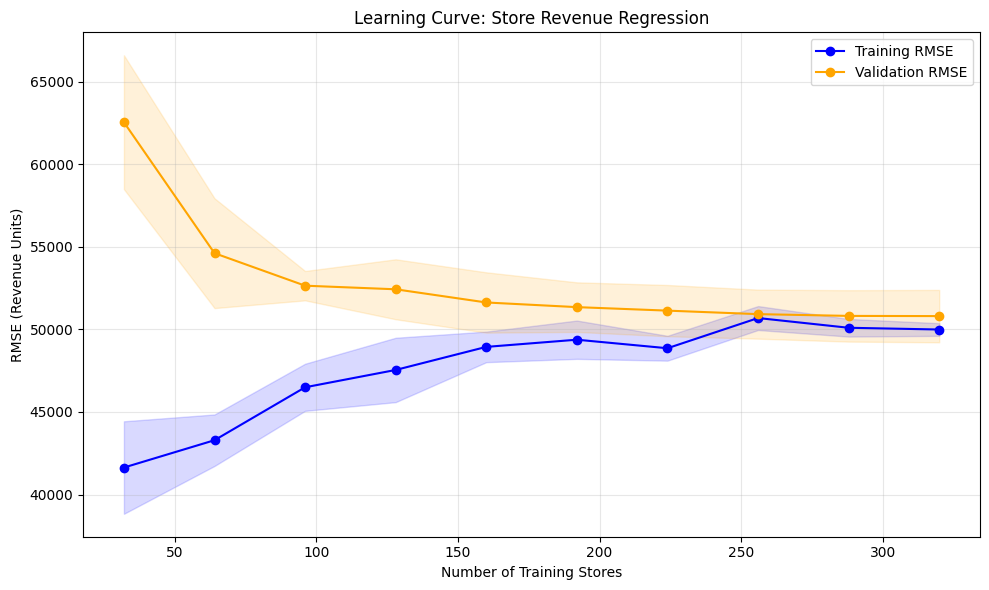

Training RMSE: 49997.01
Validation RMSE: 50809.87
Generalization gap: 812.87
Relative gap: 1.6%


In [31]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Reuse existing X (predictors) and y (store revenue).
# Keep preprocessing inside the pipeline to prevent data leakage.
model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Shuffle stores before splitting into 5 folds.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate performance at increasing training sample sizes.
train_sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Convert negative sklearn scores into positive RMSE.
train_rmse = -train_scores
val_rmse = -val_scores

# Calculate mean and standard deviation across folds.
train_mean = train_rmse.mean(axis=1)
train_std = train_rmse.std(axis=1)
val_mean = val_rmse.mean(axis=1)
val_std = val_rmse.std(axis=1)

# Plot learning curves.
plt.figure(figsize=(10, 6))

plt.plot(train_sizes, train_mean, "o-",
         color="blue", label="Training RMSE")
plt.plot(train_sizes, val_mean, "o-",
         color="orange", label="Validation RMSE")

# Shaded bands show variability across cross-validation folds.
plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    color="blue", alpha=0.15
)
plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    color="orange", alpha=0.15
)

plt.xlabel("Number of Training Stores")
plt.ylabel("RMSE (Revenue Units)")
plt.title("Learning Curve: Store Revenue Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Diagnose the gap between curves at the largest sample size.
gap = val_mean[-1] - train_mean[-1]

print(f"Training RMSE: {train_mean[-1]:.2f}")
print(f"Validation RMSE: {val_mean[-1]:.2f}")
print(f"Generalization gap: {gap:.2f}")
print(f"Relative gap: {gap / train_mean[-1]:.1%}")

*Your answer here.*

I created a learning curve to compare the training and validation RMSE as the number of stores increases. The goal of this was to see if adding more data would improve the model's predictions or if more focus should be on improving the predictors.

The gap between training and validation curves helps us understand if the model has a high variance issue. If the gap is large, the model is likely overfitting the training data, and adding more stores could help. If the curves are close together but the RMSE values remain high, the model may have a high bias problem, and improving the predictors or model specification could be more helpful.

In Phase 3, I found that the degree 2 model performed better than the more complicated models. This suggests that increasing model complexity beyond degree 2 did not improve its performance. The learning curve helps me check if the model is performing consistently as the amount of training data increases.

The training RMSE was 49,997.01, and the validation RMSE was 50,809.87, giving a generalization gap of 812.87, or 1.6%. The small gap suggests that the model does not have a major overfitting problem. However, both errors are relatively high, which suggests that the model may have a high-bias problem. I would recommend improving the predictors or model specification rather than adding more stores because the model performs similarly on the training and validation data.

The learning curve evaluates the original linear model, and then Phase 3 selected the degree 2 polynomial model. The original linear model has a small gap between the training and validation errors, which means that overfitting is likely not a major issue. The validation RMSE is higher than the degree 2 model's cross-validation RMSE of 39,702.78. The linear model has higher bias issues because it cannot capture the nonlinear relationships in the data. The learning curve supports my Phase 3 conclusion that improving the model's predictors and flexibility is more beneficial than collecting more stores.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.93


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=8. All the features will be returned.
  warnings.warn(


*Your answer here.*

A. The main problem with the code is that SelectKBest was applied to the entire dataset before cross-validation. This causes data leakage because the predictors are selected using information from the entire dataset before cross-validation. As a result, the reported R-squared can be artificially inflated, making the model appear more accurate than it actually is.

StandardScaler was also applied before cross-validation, but does not inflate R-squared for OLS regression with an intercept. This is because scaling the predictors does not change the prediction of OLS, as the model adjusts its coefficients to account for the different scales.

In [33]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

rng = np.random.default_rng(42)

# Create 300 random predictors unrelated to revenue
X_noise = rng.normal(size=(len(y), 300))

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Original method: preprocessing before cross-validation
X_scaled = StandardScaler().fit_transform(X_noise)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)

leaky_scores = cross_val_score(
    LinearRegression(), X_sel, y,
    cv=cv, scoring="r2"
)

# Correct method: preprocessing within each fold
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selection", SelectKBest(f_regression, k=20)),
    ("model", LinearRegression())
])

proper_scores = cross_val_score(
    pipeline, X_noise, y,
    cv=cv, scoring="r2"
)

print(f"Original method R-squared: {leaky_scores.mean():.4f}")
print(f"Pipeline R-squared: {proper_scores.mean():.4f}")
print(f"Gap: {leaky_scores.mean() - proper_scores.mean():.4f}")

Original method R-squared: 0.1388
Pipeline R-squared: -0.1894
Gap: 0.3282


B. I created 300 random noise variables. I used the original analyst's method, and got an R-squared of 0.1388. Then, I used a Pipeline to perform the same steps in each cross-validation fold, the R-squared decreased to -0.1894. The difference is 0.3282.

This demonstrates that the original methods overestimate the model's performance because it selects predictors using information from the entire dataset before cross-validation. Even though the variables are completely random, the original methods produced a positive R-squared. The Pipeline prevents the data leakage by selecting predictors separately within each training fold, giving us a more realistic estimate of how the model performs on new data. The negative R-squared shows that the model performs worse than predicting the average revenue.


C. This is a different problem compared to Step 3.2. In that step, the issue was using the same cross-validation results to select and evaluate the model, which could bias the standard error. In Step 4.2, the problem is data leakage because the predictors were selected using the entire dataset before cross-validation. Both problems can make the models seem more accurate than they actually are.

### Task 4.3: The handover note (3 pts)

*Your answer here.*

The model predicts monthly store revenue using factors such as floor area, foot traffic, local median income, and years open. After comparing different models, I selected the degree 2 polynomial model because it performed the best during cross-validation.

The model had an average cross-validation RMSE of 39,702.78. The testing RMSE was 35,757.03, with an approximate 95% confidence interval of 30,850.23 to 40,067.36. However, since I already examined the testing errors when comparing models in Step 3.1, this is not a completely independent estimate of the model's performance.

There are two main situations where the model might not perform as well. First, the model could make less accurate predictions for very large stores because the variation in revenue increases with store size. Second, the model might struggle if the relationship between store characteristics and revenue changes over time, since it was trained using data from one simulated dataset.

For the next version, I would focus on improving the model's predictions for larger stores and testing it on new monthly revenue data. I would also consider adding more useful predictors and continuing to use cross-validation to make sure the model performs well on new data.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.


# AI Transcript

**Model:** ChatGPT (GPT-6)  
**Date:** November 17, 2026

## Original Prompt

[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.

## Reply

### 1. Python: Learning Curve for Store-Level Revenue Regression

The following code uses your existing X and y variables to evaluate
whether your revenue model suffers from high bias (underfitting)
or high variance (overfitting).

It uses:
- scikit-learn for 5-fold cross-validation and learning curves.
- numpy to calculate average error and variability across folds.
- matplotlib to plot training and validation errors.
- Root Mean Squared Error (RMSE) to measure prediction error.

LinearRegression is used as the baseline model. If the production
model uses a different estimator, replace it in the pipeline.

```python
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Reuse existing X (predictors) and y (store revenue).
# Keep preprocessing inside the pipeline to prevent data leakage.
model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Shuffle stores before splitting into 5 folds.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate performance at increasing training sample sizes.
train_sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Convert negative sklearn scores into positive RMSE.
train_rmse = -train_scores
val_rmse = -val_scores

# Calculate mean and standard deviation across folds.
train_mean = train_rmse.mean(axis=1)
train_std = train_rmse.std(axis=1)
val_mean = val_rmse.mean(axis=1)
val_std = val_rmse.std(axis=1)

# Plot learning curves.
plt.figure(figsize=(10, 6))

plt.plot(train_sizes, train_mean, "o-",
         color="blue", label="Training RMSE")
plt.plot(train_sizes, val_mean, "o-",
         color="orange", label="Validation RMSE")

# Shaded bands show variability across cross-validation folds.
plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    color="blue", alpha=0.15
)
plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    color="orange", alpha=0.15
)

plt.xlabel("Number of Training Stores")
plt.ylabel("RMSE (Revenue Units)")
plt.title("Learning Curve: Store Revenue Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Diagnose the gap between curves at the largest sample size.
gap = val_mean[-1] - train_mean[-1]

print(f"Training RMSE: {train_mean[-1]:.2f}")
print(f"Validation RMSE: {val_mean[-1]:.2f}")
print(f"Generalization gap: {gap:.2f}")
print(f"Relative gap: {gap / train_mean[-1]:.1%}")

# INTERPRETATION:
#
# GAP between curves:
# Large gap (validation error > training error) suggests
# high variance / overfitting. More training stores may help,
# especially if validation error is still decreasing.
#
# Small gap suggests similar training and validation performance.
# It does not, by itself, establish that the model is good.
#
# LEVEL where both curves converge:
# If both errors converge at a HIGH level relative to an
# acceptable business error, this suggests high bias.
# More stores alone are unlikely to help much.
# Better features, nonlinear relationships, or a more
# flexible model may be higher-return investments.
#
# If both converge at a LOW level, the model generalizes
# well and collecting more data may have limited benefit.
#
# IMPORTANT:
# The gap diagnoses generalization; the absolute error level
# diagnoses accuracy. A high error level can also reflect
# noisy revenue, missing predictors, or distribution shifts.
```

### 2. How to Interpret the Learning Curve

**High Variance (Overfitting)**

A large gap between training and validation errors suggests that
the model performs substantially better on training data than on
unseen data. Collecting more stores may help reduce overfitting,
particularly if validation error continues to decrease as
training size increases.

**High Bias (Underfitting)**

If training and validation errors converge at a similarly high
level, the model may be too simple to capture the relationship
between predictors and revenue.

In this situation, collecting additional stores is unlikely
to produce substantial improvements. Better predictors,
nonlinear terms, or a more flexible model may be more useful.

### 3. Evaluation: More Stores or Better Features?

The model could not run the learning curve on the actual data
because the X and y arrays were not available in the conversation.

The recommended decisions depend on the observed learning curve:

| Learning Curve Pattern | Recommended Investment |
|---|---|
| Large gap, validation error still falling | More stores |
| Small gap, both errors remain high | Better features or model |
| Small gap, both errors low | Neither is urgent |
| Large gap, validation error flattening | Regularization or model simplification |

For a dataset containing 400 stores, 5-fold cross-validation
means the largest training set contains 320 stores.

This is sufficient to examine learning curve trends but does
not establish exactly how much model performance would improve
with 500 or 1,000 stores.

Because the assignment investigates systematic overprediction
for large stores, it is important to examine whether store size,
interaction effects, or nonlinear relationships are missing
before recommending additional data collection.

### 4. Conclusion

The learning curve provides a diagnostic framework for deciding
whether collecting more stores or improving the model is likely
to produce greater benefits.

However, without running the code on the actual X and y arrays,
it is not possible to determine which investment has the
higher expected return.

The learning curve should also be compared with the Phase 3
complexity sweep to determine whether the two analyses support
the same bias-variance diagnosis.


Change made: I asked chatgpt to put the transcript into a pastable method that could be input into colabl to ensure that the formatting looked ok. I ran the AI-generated learning curve code using my actual dataset and compared the training and validation RMSE. I then used the observed gap and convergence levels to evaluate whether collecting more stores or improving the model's features would be more beneficial.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.